# 06. Referral model: logistic regression with multiple imputation inside cross-validation

**Track 3 · Owner: Chang (Aphisit) · Action items B0, B1, B2, B3, G1, G2, G3, G4 · Criterion 6 · Professor F2**

| Item | What this notebook delivers | Output |
|------|-----------------------------|--------|
| B0 | Complete-case model, stratified 5-fold, out-of-fold (OOF) predictions for Track 5 | `data/interim/oof_simple.csv` |
| B1 | Multiple imputation **inside** each fold (training fold only, no outcome), m = 5, predictions averaged | `data/interim/oof_final.csv` |
| G2 | Baselines: intercept-only and age-only, same folds | `model_performance*.csv`, `model_repeated_cv.csv` |
| G4 | Calibration: reliability diagram, calibration intercept and slope, Brier, Hosmer–Lemeshow, Spiegelhalter | `model_calibration*.csv`, `model_calibration.png` |
| G1 | Rubin's-rules odds ratios in clinical units + absolute risk for example patients | `model_or_mi.csv`, `model_example_patients.csv` |
| B3 | Complete-case vs MI odds ratios side by side | `model_or_cc_vs_mi.csv`, `model_or_forest.png` |
| G3 | Diagnostics: spline linearity checks, influence, VIF, separation | `model_linearity*`, `model_influence*`, `model_vif.csv` |
| B2 | Methods paragraph on the pooling decision | last section |

Shared code is in [`src/modeling.py`](../src/modeling.py), so Track 5 can re-run exactly this pipeline inside the whole-pipeline bootstrap (A4).

**Reproducibility.** All randomness is seeded from `SEED = 42` in `src/config.py` (CV split: `SEED`; imputation draw k: `SEED + k`; repeated CV: `SEED + 1000 + r`). Every saved number is rounded to 10 significant digits, so two runs give byte-identical files (checked: two consecutive runs and a fresh clone produced identical hashes for all 19 output files). Runtime is about 70 seconds.

**How to read the intervals.** A 95% interval comes from a procedure that captures the true value in about 95% of repeated samples. It is not a 95% probability statement about this particular interval.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

from src.config import ALPHA, DATA_INTERIM, FIGURES, N_BOOT, N_FOLDS, N_IMPUTATIONS, SEED, TABLES
from src.data import load_raw
from src.modeling import (
    AGE_ONLY_COLS, LABELS, MODEL_COLS, UNITS, boot_metrics, calibration_intercept_slope,
    design, fit_sm_logit, impute_full, metrics, oof_predictions, prepare, rubin_pool,
)
from src.stats_utils import fmt_ci, wilson_ci

for d in (FIGURES, TABLES, DATA_INTERIM):
    d.mkdir(parents=True, exist_ok=True)

raw = load_raw()
df = prepare(raw)                      # drops the single gender "Other" record
X = design(df)                         # clinical units; BMI NaN where missing
y = df["stroke"].to_numpy(int)
expit = lambda z: 1 / (1 + np.exp(-z))
# Round every saved number to 10 significant digits so files are byte-identical
# across machines (BLAS can differ in the last ~15th digit).
FLOAT_FMT = "%.10g"

print(f"Raw: {len(raw):,} rows | modelling: {len(df):,} rows, {y.sum()} strokes "
      f"({y.mean():.2%}) | BMI missing: {X['bmi'].isna().sum()}")

Raw: 5,110 rows | modelling: 5,109 rows, 249 strokes (4.87%) | BMI missing: 201


## Model specification (fixed before looking at performance)

- **Predictors** are the proposal's two groups (section 7): *non-modifiable* age, gender and heart disease; *modifiable* hypertension, glucose, BMI and smoking status. ever_married, work_type and Residence_type are **not** in the referral model: they are social proxies a physician cannot act on, and ever_married/work_type mostly re-encode age. They are used as auxiliary variables in the BMI imputation model.
- **Units:** age per 10 years, glucose per 50 mg/dL, BMI per 5 kg/m² (KB 08).
- **Linear terms** for the continuous predictors; linearity is checked with splines in G3.
- **Gender "Other" (1 record) is excluded** from the modelling data, because gender is a predictor and one record cannot support a coefficient (cleaning log decision 8). Modelling n = 5,109 with 249 strokes.
- **Size:** 9 parameters + intercept, about 28 events per parameter, inside the 10–20 rule of thumb (KB 08).

In [2]:
group = {"age": "Non-modifiable", "male": "Non-modifiable", "heart_disease": "Non-modifiable"}
spec = pd.DataFrame({
    "column": MODEL_COLS,
    "predictor": [LABELS[c] for c in MODEL_COLS],
    "group": [group.get(c, "Modifiable") for c in MODEL_COLS],
})
display(spec)
print(f"{len(MODEL_COLS)} parameters (+ intercept); events per parameter = {y.sum() / len(MODEL_COLS):.1f}")

,column,predictor,group
0,age,Age (per 10 years),Non-modifiable
1,male,Male (vs female),Non-modifiable
2,heart_disease,Heart disease,Non-modifiable
3,hypertension,Hypertension,Modifiable
4,avg_glucose_level,Glucose (per 50 mg/dL),Modifiable
5,bmi,BMI (per 5 kg/m²),Modifiable
6,smoke_former,Formerly smoked (vs never),Modifiable
7,smoke_current,Smokes (vs never),Modifiable
8,smoke_unknown,Smoking unknown (vs never),Modifiable


9 parameters (+ intercept); events per parameter = 27.7


## B0. Complete-case model with out-of-fold predictions (for Track 5 to start)

Stratified 5-fold CV (`StratifiedKFold`, shuffled, `SEED`); every fold keeps the 4.9% stroke rate. In each fold the model is fitted on training rows with BMI recorded and used to predict test rows with BMI recorded.

**Caution for Track 5:** the 201 BMI-missing patients (40 strokes) cannot be scored, so this file has a base rate of 4.26%, not 4.87%. Use it only to build the threshold code; switch to `oof_final.csv` for the reported results. The folds are the same as in `oof_final.csv`.

In [3]:
oof_cc = oof_predictions(df, models=("complete_case",))
oof_simple = (oof_cc.dropna(subset=["p_complete_case"])
              .rename(columns={"p_complete_case": "p"})[["row_id", "fold", "stroke", "p"]])
oof_simple.to_csv(DATA_INTERIM / "oof_simple.csv", index=False, float_format=FLOAT_FMT)
print(f"oof_simple.csv: {len(oof_simple):,} patients, {oof_simple['stroke'].sum()} strokes "
      f"(201 BMI-missing patients have no complete-case prediction)")
print(oof_simple.groupby("fold")["stroke"].agg(["size", "sum", "mean"]).round(4))

oof_simple.csv: 4,908 patients, 209 strokes (201 BMI-missing patients have no complete-case prediction)
      size  sum    mean
fold                   
0      978   41  0.0419
1      983   40  0.0407
2      981   45  0.0459
3      986   41  0.0416
4      980   42  0.0429


## B1. Multiple imputation inside cross-validation (professor F2)

**Order (split first, impute second).** For each of the 5 folds:
1. Fit the BMI imputation model on the **training fold only**.
2. For k = 1…m (m = 5), draw one set of imputation parameters and fill in missing BMI in both the training and the test fold with that draw.
3. Fit the logistic model on the completed training fold and predict the completed test fold.
4. Average the m predicted probabilities for each test patient (pre-specified pooling; see B2).

**Imputation model.** Bayesian normal linear regression of log(BMI) on age, gender, hypertension, heart disease, glucose, smoking and the auxiliary variables (van Buuren 2018, Algorithm 3.1). Each draw samples the regression coefficients and residual variance from their posterior and then adds residual noise, so the m datasets differ in both, which makes it *proper* multiple imputation. Imputing on the log scale keeps BMI positive and handles the right skew.

**Two imputation set-ups (KB 03):**
- *Prediction (inside CV):* the outcome is **not** used, because a new patient's stroke status is unknown when the model is used.
- *Inference (G1, full data):* the outcome **is** used (Moons et al., 2006); otherwise the BMI–stroke association is biased toward zero.

`oof_final.csv` holds, for every patient, the OOF risk from each model, with age, gender, hypertension, heart disease and the BMI-missing flag (for Track 4's H2 error-rate table and Track 1's D4).

The check below uses the inference set-up.

oof_final.csv: 5,109 rows; columns: ['row_id', 'fold', 'stroke', 'p_intercept', 'p_age_only', 'p_complete_case', 'p_mi', 'p_mi_indicator', 'age', 'gender', 'hypertension', 'heart_disease', 'bmi_missing']


,set,n,mean,sd,min,max
0,Observed BMI,4908,28.89,7.85,10.30,97.60
1,Imputed BMI (pooled over m = 5),1005,30.07,7.68,12.08,66.61


Mean imputed BMI by imputation: [np.float64(29.61), np.float64(29.62), np.float64(30.54), np.float64(29.96), np.float64(30.58)]


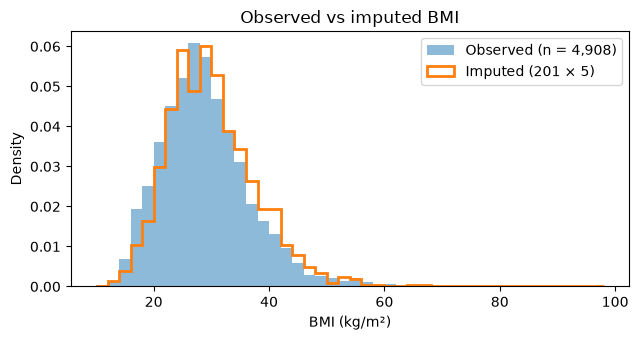

In [4]:
oof = oof_predictions(df)   # intercept, age-only, complete-case, MI, MI + indicator
oof = oof.merge(df[["row_id", "age", "gender", "hypertension", "heart_disease"]], on="row_id")
oof["gender"] = oof["gender"].astype(str)
oof["bmi_missing"] = X["bmi"].isna().astype(int).to_numpy()
oof.to_csv(DATA_INTERIM / "oof_final.csv", index=False, float_format=FLOAT_FMT)
print(f"oof_final.csv: {len(oof):,} rows; columns: {list(oof.columns)}")

# Imputation check (inference set-up, full data, outcome in the imputation model)
Xs = impute_full(df, m=N_IMPUTATIONS, seed=SEED)
miss = X["bmi"].isna().to_numpy()
obs_bmi = X.loc[~miss, "bmi"] * UNITS["bmi"]
imp_bmi = np.concatenate([Xm.loc[miss, "bmi"].to_numpy() * UNITS["bmi"] for Xm in Xs])
imp_check = pd.DataFrame({
    "set": ["Observed BMI", f"Imputed BMI (pooled over m = {N_IMPUTATIONS})"],
    "n": [len(obs_bmi), len(imp_bmi)],
    "mean": [obs_bmi.mean(), imp_bmi.mean()],
    "sd": [obs_bmi.std(), imp_bmi.std()],
    "min": [obs_bmi.min(), imp_bmi.min()],
    "max": [obs_bmi.max(), imp_bmi.max()],
}).round(2)
display(imp_check)
print("Mean imputed BMI by imputation:", [round(Xm.loc[miss, "bmi"].mean() * UNITS["bmi"], 2) for Xm in Xs])

fig, ax = plt.subplots(figsize=(6.5, 3.5))
bins = np.arange(10, 100, 2)
ax.hist(obs_bmi, bins=bins, density=True, alpha=0.5, label=f"Observed (n = {len(obs_bmi):,})")
ax.hist(imp_bmi, bins=bins, density=True, histtype="step", lw=2, label=f"Imputed ({miss.sum()} × {N_IMPUTATIONS})")
ax.set_xlabel("BMI (kg/m²)"); ax.set_ylabel("Density"); ax.legend()
ax.set_title("Observed vs imputed BMI")
fig.tight_layout(); fig.savefig(FIGURES / "model_bmi_imputation_check.png", bbox_inches="tight"); plt.show()

**Imputation check.** Imputed BMI is centred slightly higher than observed BMI (about 30.1 vs 28.9 kg/m²) with a similar spread and a plausible range. That is expected: the BMI-missing patients are older and have higher glucose (Track 1, D1), and both predict higher BMI.

## G2. Out-of-fold performance vs baselines

Metrics are computed on the OOF predictions (no patient is scored by a model that saw them):
- **AUC** (discrimination, reported for completeness as the proposal says), **average precision** (more informative at 5% prevalence);
- **Brier score** and **scaled Brier** = 1 − Brier / Brier(intercept-only), where 0 means no better than giving everyone the base rate;
- **calibration intercept and slope** (see G4).

**CIs:** stratified percentile bootstrap over patients (B = 10,000, every resample keeps 249 strokes), using the **same resamples for every model**, so differences between models get paired CIs. The bootstrap resamples the evaluation set but does not refit the models; the repeated-CV check below covers the variability from the fold split.

Complete case can only score the 4,908 patients with BMI recorded, so it is compared with the MI model on exactly those patients.

In [5]:
MODELS = {
    "Intercept only": "p_intercept",
    "Age only": "p_age_only",
    "Full model (MI)": "p_mi",
    "Full model (MI) + BMI-missing indicator": "p_mi_indicator",
}

def perf_table(frame, models, B, seed=SEED):
    yy = frame["stroke"].to_numpy(int)
    boots = boot_metrics(yy, {k: frame[v].to_numpy() for k, v in models.items()}, B=B, seed=seed)
    rows = []
    for name, col in models.items():
        pt = metrics(yy, frame[col].to_numpy())
        q = lambda k: boots[(name, k)].quantile([ALPHA / 2, 1 - ALPHA / 2]).to_numpy()
        rows.append({
            "model": name, "n": len(yy), "strokes": int(yy.sum()),
            "auc": pt["auc"], "auc_low": q("auc")[0], "auc_high": q("auc")[1],
            "brier": pt["brier"], "brier_low": q("brier")[0], "brier_high": q("brier")[1],
            "scaled_brier": pt["scaled_brier"], "scaled_brier_low": q("scaled_brier")[0],
            "scaled_brier_high": q("scaled_brier")[1],
            "avg_precision": pt["avg_precision"], "log_loss": pt["log_loss"],
            "cal_intercept": pt["cal_intercept"], "cal_slope": pt["cal_slope"],
        })
    return pd.DataFrame(rows), boots

perf_all, boots_all = perf_table(oof, MODELS, B=N_BOOT)

# Complete case can only score the 4,908 patients with BMI recorded:
# compare it with the MI model on exactly those patients.
cc_rows = oof[oof["p_complete_case"].notna()]
perf_cc, boots_cc = perf_table(cc_rows, {"Age only": "p_age_only", "Full model (complete case)": "p_complete_case",
                                         "Full model (MI)": "p_mi"}, B=N_BOOT)
perf_all["evaluated_on"] = "All patients"
perf_cc["evaluated_on"] = "BMI recorded only"
perf = pd.concat([perf_all, perf_cc], ignore_index=True)
perf.to_csv(TABLES / "model_performance.csv", index=False, float_format=FLOAT_FMT)

show = perf[["evaluated_on", "model", "n", "strokes"]].copy()
show["AUC (95% CI)"] = [fmt_ci(r.auc, r.auc_low, r.auc_high, 3) for r in perf.itertuples()]
show["Brier (95% CI)"] = [fmt_ci(r.brier, r.brier_low, r.brier_high, 4) for r in perf.itertuples()]
show["Scaled Brier (95% CI)"] = [fmt_ci(r.scaled_brier, r.scaled_brier_low, r.scaled_brier_high, 3) for r in perf.itertuples()]
show["Avg precision"] = perf["avg_precision"].round(3)
show["Cal. intercept"] = perf["cal_intercept"].round(3)
show["Cal. slope"] = perf["cal_slope"].round(2)
display(show)

,evaluated_on,model,n,strokes,AUC (95% CI),Brier (95% CI),Scaled Brier (95% CI),Avg precision,Cal. intercept,Cal. slope
0,All patients,Intercept only,5109,249,0.500 (0.500 to 0.500),0.0464 (0.0464 to 0.0464),-0.000 (-0.000 to 0.000),0.049,0.000,NaN
1,All patients,Age only,5109,249,0.833 (0.812 to 0.853),0.0426 (0.0418 to 0.0435),0.080 (0.062 to 0.098),0.164,-0.001,0.99
2,All patients,Full model (MI),5109,249,0.839 (0.818 to 0.859),0.0427 (0.0417 to 0.0437),0.079 (0.058 to 0.101),0.181,-0.000,0.95
3,All patients,Full model (MI) + BMI-missing indicator,5109,249,0.849 (0.828 to 0.868),0.0421 (0.0409 to 0.0434),0.092 (0.065 to 0.118),0.203,-0.002,0.95
4,BMI recorded only,Age only,4908,209,0.835 (0.813 to 0.856),0.0379 (0.0371 to 0.0387),0.070 (0.050 to 0.091),0.151,-0.130,0.99
5,BMI recorded only,Full model (complete case),4908,209,0.844 (0.822 to 0.865),0.0376 (0.0366 to 0.0386),0.077 (0.054 to 0.101),0.173,0.002,0.94
6,BMI recorded only,Full model (MI),4908,209,0.844 (0.822 to 0.864),0.0377 (0.0368 to 0.0387),0.074 (0.051 to 0.098),0.171,-0.121,0.98


In [6]:
# Paired differences (same bootstrap resamples for both models)
def paired(boots, a, b, metric):
    d = boots[(a, metric)] - boots[(b, metric)]
    return d.mean(), *d.quantile([ALPHA / 2, 1 - ALPHA / 2]).to_numpy()

pairs = [
    (boots_all, perf_all, "Full model (MI)", "Age only", "All patients"),
    (boots_all, perf_all, "Full model (MI) + BMI-missing indicator", "Full model (MI)", "All patients"),
    (boots_cc, perf_cc, "Full model (complete case)", "Full model (MI)", "BMI recorded only"),
]
rows = []
for boots, pt, a, b, where in pairs:
    for metric in ["auc", "scaled_brier", "brier"]:
        est = pt.set_index("model").loc[a, metric] - pt.set_index("model").loc[b, metric]
        _, lo, hi = paired(boots, a, b, metric)
        rows.append({"evaluated_on": where, "comparison": f"{a} − {b}", "metric": metric,
                     "difference": est, "ci_low": lo, "ci_high": hi})
diffs = pd.DataFrame(rows)
diffs.to_csv(TABLES / "model_performance_differences.csv", index=False, float_format=FLOAT_FMT)
display(diffs.assign(**{"difference (95% CI)": [fmt_ci(r.difference, r.ci_low, r.ci_high, 4) for r in diffs.itertuples()]})
        [["evaluated_on", "comparison", "metric", "difference (95% CI)"]])

,evaluated_on,comparison,metric,difference (95% CI)
0,All patients,Full model (MI) − Age only,auc,0.0057 (-0.0010 to 0.0126)
1,All patients,Full model (MI) − Age only,scaled_brier,-0.0011 (-0.0128 to 0.0112)
2,All patients,Full model (MI) − Age only,brier,0.0001 (-0.0005 to 0.0006)
3,All patients,Full model (MI) + BMI-missing indicator − Full...,auc,0.0100 (0.0036 to 0.0166)
4,All patients,Full model (MI) + BMI-missing indicator − Full...,scaled_brier,0.0124 (-0.0040 to 0.0292)
5,All patients,Full model (MI) + BMI-missing indicator − Full...,brier,-0.0006 (-0.0014 to 0.0002)
6,BMI recorded only,Full model (complete case) − Full model (MI),auc,0.0008 (-0.0029 to 0.0042)
7,BMI recorded only,Full model (complete case) − Full model (MI),scaled_brier,0.0030 (-0.0025 to 0.0085)
8,BMI recorded only,Full model (complete case) − Full model (MI),brier,-0.0001 (-0.0003 to 0.0001)


**Results.**
- The full model (MI) has OOF AUC **0.839 (95% CI 0.818 to 0.859)**, against **0.833 (0.812 to 0.853)** for age alone. The paired difference is **+0.006 (−0.001 to 0.013)**. The scaled Brier score is essentially the same (difference −0.001, −0.013 to 0.011). Average precision is somewhat higher (0.181 vs 0.164).
- **Once age is known, the other six predictors add very little discrimination or accuracy.** This bears directly on professor point F3. It is reported here as model validation, **not** as a confirmatory test: the decision-relevant hypotheses (C1) are not registered yet. The comparison that matters for the referral decision is net benefit across thresholds (Track 5, A3).
- Intercept-only: AUC 0.5 and scaled Brier 0 by construction. Both models beat it clearly (scaled Brier about 0.08).
- **Complete case vs MI** on the 4,908 patients with BMI recorded: AUC 0.844 vs 0.844 (difference 0.001, −0.003 to 0.004). The two are equivalent on these patients. The MI model's calibration intercept on this subset is −0.12, meaning it predicts slightly too high for BMI-recorded patients. It was trained on a population that includes the high-risk BMI-missing group, while its predictors can't tell who that group is.
- **BMI-missing indicator (for Track 1, D4):** adding it raises AUC by **0.010 (0.004 to 0.017)** and average precision from 0.181 to 0.203. We still leave it out of the referral model: (1) it describes how the record was kept, not the patient, so it is not something the physician can act on; (2) Track 1 found the excess risk is not explained by covariates (likely MNAR or reverse causation: BMI may go unrecorded *because* the patient had a stroke), so the gain may be outcome leakage through the data-collection process; (3) in a new clinic, missingness would arise differently and the coefficient would not transfer.

### Repeated CV: how much does the fold split matter?

One 5-fold split is one random partition. Re-running the whole pipeline with 20 different splits (seeds `SEED + 1000 + r`) shows how much the OOF metrics move because of the split alone.

In [7]:
N_REPEATS = 20
rep_rows = []
for r in range(N_REPEATS):
    o = oof_predictions(df, seed=SEED + 1000 + r, models=("age_only", "mi"))
    for col, name in [("p_age_only", "Age only"), ("p_mi", "Full model (MI)")]:
        mt = metrics(o["stroke"], o[col])
        rep_rows.append({"repeat": r, "model": name, "auc": mt["auc"], "scaled_brier": mt["scaled_brier"],
                         "cal_slope": mt["cal_slope"]})
rep = pd.DataFrame(rep_rows)
rep.to_csv(TABLES / "model_repeated_cv.csv", index=False, float_format=FLOAT_FMT)
summary = rep.groupby("model")[["auc", "scaled_brier", "cal_slope"]].agg(["mean", "std", "min", "max"]).round(4)
display(summary)
wide = rep.pivot(index="repeat", columns="model", values="auc")
d_auc = wide["Full model (MI)"] - wide["Age only"]
print(f"AUC(MI) − AUC(age only) across {N_REPEATS} CV splits: mean {d_auc.mean():.4f}, "
      f"range {d_auc.min():.4f} to {d_auc.max():.4f}; MI higher in {(d_auc > 0).sum()}/{N_REPEATS} splits")

auc                         scaled_brier                  \
                   mean     std     min     max         mean     std     min   
model                                                                          
Age only         0.8339  0.0003  0.8333  0.8344       0.0812  0.0004  0.0801   
Full model (MI)  0.8396  0.0019  0.8346  0.8421       0.0816  0.0029  0.0750   

                        cal_slope                          
                    max      mean     std     min     max  
model                                                      
Age only         0.0818    0.9950  0.0023  0.9907  0.9995  
Full model (MI)  0.0857    0.9567  0.0135  0.9254  0.9740

AUC(MI) − AUC(age only) across 20 CV splits: mean 0.0057, range 0.0005 to 0.0079; MI higher in 20/20 splits


**Results.** Across 20 splits the MI model's AUC has a standard deviation of 0.002 (range 0.835 to 0.842). It beats age-only in **all 20 splits, but by only 0.0005 to 0.008**. The main split above is typical, not lucky. Calibration slope ranges from 0.93 to 0.97.

## G4. Calibration (needed before applying any threshold)

On the OOF predictions:
- **Reliability diagram:** patients grouped into deciles of predicted risk; observed stroke rate with Wilson 95% CIs; LOESS smooth (no robustness iterations, which would discard the rare strokes as outliers).
- **Calibration intercept** (calibration-in-the-large: logit(y) ~ offset(logit p̂), ideal 0) and **slope** (y ~ logit p̂, ideal 1; below 1 means predictions too extreme, i.e. overfitting), with stratified bootstrap CIs (B = 1,000, because each resample refits two GLMs).
- **Hosmer–Lemeshow** (deciles, 8 df) and **Spiegelhalter's z** as formal calibration tests. HL depends on the binning and has low power, so neither test is used alone (KB 08).

In [8]:
N_BOOT_CAL = 1_000   # each resample refits two small GLMs

def calib_bins(yy, p, n_bins=10):
    q = pd.qcut(p, n_bins, labels=False, duplicates="drop")
    rows = []
    for b in np.unique(q):
        s = q == b
        k, n = int(yy[s].sum()), int(s.sum())
        lo, hi = proportion_confint(k, n, alpha=ALPHA, method="wilson")
        rows.append({"bin": b + 1, "n": n, "strokes": k, "mean_pred": p[s].mean(),
                     "observed": k / n, "obs_low": lo, "obs_high": hi})
    return pd.DataFrame(rows)

def hosmer_lemeshow(yy, p, g=10):
    q = pd.qcut(p, g, labels=False, duplicates="drop")
    tab = pd.DataFrame({"y": yy, "p": p, "q": q}).groupby("q").agg(o=("y", "sum"), e=("p", "sum"), n=("y", "size"))
    hl = (((tab.o - tab.e) ** 2) / (tab.e * (1 - tab.e / tab.n))).sum()
    return hl, stats.chi2.sf(hl, len(tab) - 2), len(tab) - 2   # OOF: some use g df; g-2 is conservative-side convention

def spiegelhalter(yy, p):
    num = np.sum((yy - p) * (1 - 2 * p))
    den = np.sqrt(np.sum((1 - 2 * p) ** 2 * p * (1 - p)))
    z = num / den
    return z, 2 * stats.norm.sf(abs(z))

rng = np.random.default_rng(SEED)
pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
idx_boot = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(N_BOOT_CAL)]

cal_rows, bins_all = [], []
for name, col in [("Age only", "p_age_only"), ("Full model (MI)", "p_mi")]:
    p = oof[col].to_numpy()
    citl, slope = calibration_intercept_slope(y, p)
    bcal = np.array([calibration_intercept_slope(y[i], p[i]) for i in idx_boot])
    hl, hl_p, hl_df = hosmer_lemeshow(y, p)
    z, z_p = spiegelhalter(y, p)
    cal_rows.append({
        "model": name, "mean_predicted": p.mean(), "observed_rate": y.mean(),
        "cal_intercept": citl, "cal_intercept_low": np.quantile(bcal[:, 0], ALPHA / 2), "cal_intercept_high": np.quantile(bcal[:, 0], 1 - ALPHA / 2),
        "cal_slope": slope, "cal_slope_low": np.quantile(bcal[:, 1], ALPHA / 2), "cal_slope_high": np.quantile(bcal[:, 1], 1 - ALPHA / 2),
        "hosmer_lemeshow": hl, "hl_df": hl_df, "hl_p": hl_p, "spiegelhalter_z": z, "spiegelhalter_p": z_p,
    })
    bins_all.append(calib_bins(y, p).assign(model=name))
cal = pd.DataFrame(cal_rows)
cal_bins = pd.concat(bins_all, ignore_index=True)
cal.to_csv(TABLES / "model_calibration.csv", index=False, float_format=FLOAT_FMT)
cal_bins.to_csv(TABLES / "model_calibration_bins.csv", index=False, float_format=FLOAT_FMT)
display(cal.round(4).T)
display(cal_bins[cal_bins.model == "Full model (MI)"].round(4))

,0,1
model,Age only,Full model (MI)
mean_predicted,0.0488,0.0488
observed_rate,0.0487,0.0487
cal_intercept,-0.0006,-0.0003
cal_intercept_low,-0.0383,-0.0428
cal_intercept_high,0.0394,0.0441
cal_slope,0.9906,0.9501
cal_slope_low,0.88,0.8498
cal_slope_high,1.1156,1.0705
hosmer_lemeshow,5.0589,19.1566


,bin,n,strokes,mean_pred,observed,obs_low,obs_high,model
10,1,511,1,0.0011,0.0020,0.0003,0.0110,Full model (MI)
11,2,511,1,0.0023,0.0020,0.0003,0.0110,Full model (MI)
12,3,511,0,0.0044,0.0000,0.0000,0.0075,Full model (MI)
13,4,511,3,0.0083,0.0059,0.0020,0.0171,Full model (MI)
14,5,511,10,0.0144,0.0196,0.0107,0.0356,Full model (MI)
15,6,510,7,0.0237,0.0137,0.0067,0.0281,Full model (MI)
16,7,511,31,0.0381,0.0607,0.0431,0.0848,Full model (MI)
17,8,511,26,0.0631,0.0509,0.0350,0.0735,Full model (MI)
18,9,511,71,0.1148,0.1389,0.1116,0.1716,Full model (MI)
19,10,511,99,0.2173,0.1937,0.1618,0.2302,Full model (MI)


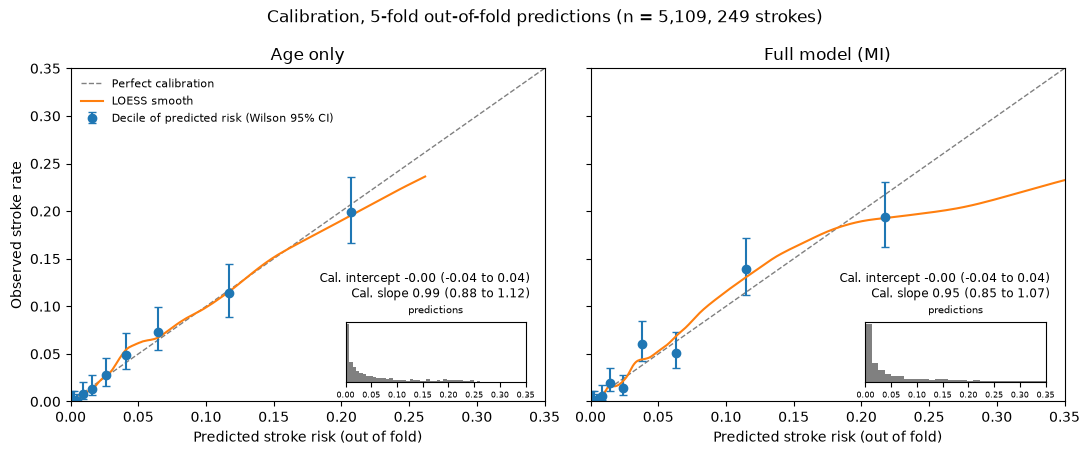

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, name, col in [(axes[0], "Age only", "p_age_only"), (axes[1], "Full model (MI)", "p_mi")]:
    b = cal_bins[cal_bins.model == name]
    p = oof[col].to_numpy()
    ax.plot([0, 0.35], [0, 0.35], color="grey", ls="--", lw=1, label="Perfect calibration")
    ax.errorbar(b.mean_pred, b.observed, yerr=[b.observed - b.obs_low, b.obs_high - b.observed],
                fmt="o", capsize=3, label="Decile of predicted risk (Wilson 95% CI)")
    sm_ = lowess(y, p, frac=0.4, it=0, return_sorted=True)   # it=0: no robustness reweighting (it would discard the rare strokes as outliers)
    ax.plot(sm_[:, 0], sm_[:, 1], lw=1.5, label="LOESS smooth")
    r = cal.set_index("model").loc[name]
    ax.text(0.97, 0.30, f"Cal. intercept {r.cal_intercept:.2f} ({r.cal_intercept_low:.2f} to {r.cal_intercept_high:.2f})\n"
                        f"Cal. slope {r.cal_slope:.2f} ({r.cal_slope_low:.2f} to {r.cal_slope_high:.2f})",
            fontsize=8.5, va="bottom", ha="right", transform=ax.transAxes)
    ax.set_xlim(0, 0.35); ax.set_ylim(0, 0.35)
    ax.set_xlabel("Predicted stroke risk (out of fold)"); ax.set_title(name)
    ins = ax.inset_axes([0.58, 0.06, 0.38, 0.18])
    ins.hist(p, bins=40, color="grey"); ins.set_yticks([]); ins.set_xlim(0, 0.35); ins.tick_params(labelsize=6)
    ins.set_title("predictions", fontsize=7)
axes[0].set_ylabel("Observed stroke rate")
axes[0].legend(loc="upper left", fontsize=8, frameon=False)
fig.suptitle(f"Calibration, {N_FOLDS}-fold out-of-fold predictions (n = {len(y):,}, {y.sum()} strokes)")
fig.tight_layout(); fig.savefig(FIGURES / "model_calibration.png", bbox_inches="tight"); plt.show()

**Results.**
- **Calibration-in-the-large is good for both models:** intercept −0.000 (−0.04 to 0.04); mean predicted risk 4.88% vs observed 4.87%.
- **Calibration slope:** 0.95 (0.85 to 1.07) for the full model and 0.99 (0.88 to 1.12) for age alone. The full model's predictions are slightly too spread out, a mild sign of overfitting, but the interval includes 1. No recalibration applied.
- **Tests disagree for the full model:** Spiegelhalter p = 0.64, Hosmer–Lemeshow χ² = 19.2 (8 df), p = 0.014 (age-only: HL p = 0.75). The HL statistic comes mostly from deciles 6–7: predicted 2.4% vs observed 1.4%, then predicted 3.8% vs observed 6.1%. Neighbouring deciles miss in opposite directions, which looks like binning noise rather than a systematic bend, and the LOESS curve follows the diagonal there. Above about 20% predicted risk the LOESS curve falls below the diagonal (top decile: predicted 21.7%, observed 19.4%): the highest predictions are a little too high, which is what a slope below 1 means. Few patients are in that range and all of them would be referred at any plausible threshold, so it doesn't affect the decision. **For Track 5:** this is the 2–6% risk range where a referral threshold is likely to fall, so read threshold results there with that in mind.

## G1. Odds ratios with Rubin's rules (inference set-up)

The full data (n = 5,109) are imputed m = 5 times with the outcome in the imputation model. The logistic model is fitted to each completed dataset (statsmodels, Wald SEs) and log-odds coefficients are pooled with Rubin's rules: pooled estimate Q̄ = mean(Q_k); total variance T = W + (1 + 1/m)·B; t reference distribution with Rubin's degrees of freedom. The table also shows the **fraction of missing information** (FMI) and, as a stability check, the same model pooled over **m = 20**.

In [10]:
def pool_fits(Xs_list, cols=MODEL_COLS):
    fits = [fit_sm_logit(Xm, y, cols) for Xm in Xs_list]
    est = np.array([f.params.to_numpy() for f in fits])
    var = np.array([np.diag(f.cov_params()) for f in fits])
    out = rubin_pool(est, var)
    out.index = ["const"] + list(cols)
    return out, fits

pooled, fits_mi = pool_fits(Xs)
Xs20 = impute_full(df, m=20, seed=SEED)
pooled20, _ = pool_fits(Xs20)

or_mi = pd.DataFrame({
    "predictor": [LABELS[c] for c in MODEL_COLS],
    "OR": np.exp(pooled.loc[MODEL_COLS, "estimate"]),
    "ci_low": np.exp(pooled.loc[MODEL_COLS, "ci_low"]),
    "ci_high": np.exp(pooled.loc[MODEL_COLS, "ci_high"]),
    "p_value": pooled.loc[MODEL_COLS, "p_value"],
    "fmi": pooled.loc[MODEL_COLS, "fmi"],
    "rubin_df": pooled.loc[MODEL_COLS, "df"],
    "OR_m20": np.exp(pooled20.loc[MODEL_COLS, "estimate"]),
    "ci_low_m20": np.exp(pooled20.loc[MODEL_COLS, "ci_low"]),
    "ci_high_m20": np.exp(pooled20.loc[MODEL_COLS, "ci_high"]),
}, index=MODEL_COLS)
or_mi.to_csv(TABLES / "model_or_mi.csv", index_label="column", float_format=FLOAT_FMT)
display(or_mi.assign(**{
    f"OR (95% CI), m = {N_IMPUTATIONS}": [fmt_ci(r.OR, r.ci_low, r.ci_high) for r in or_mi.itertuples()],
    "OR (95% CI), m = 20": [fmt_ci(r.OR_m20, r.ci_low_m20, r.ci_high_m20) for r in or_mi.itertuples()],
    "p": or_mi.p_value.map(lambda v: f"{v:.2g}"), "FMI": or_mi.fmi.round(3),
})[["predictor", f"OR (95% CI), m = {N_IMPUTATIONS}", "p", "FMI", "OR (95% CI), m = 20"]].set_index("predictor"))

,"OR (95% CI), m = 5",p,FMI,"OR (95% CI), m = 20"
predictor,,,,
Age (per 10 years),2.00 (1.81 to 2.22),1.9e-39,0.002,2.01 (1.81 to 2.23)
Male (vs female),1.01 (0.77 to 1.34),0.92,0.000,1.02 (0.77 to 1.34)
Heart disease,1.35 (0.93 to 1.95),0.12,0.000,1.35 (0.93 to 1.96)
Hypertension,1.49 (1.08 to 2.06),0.015,0.001,1.49 (1.08 to 2.05)
Glucose (per 50 mg/dL),1.23 (1.10 to 1.39),0.00049,0.004,1.23 (1.09 to 1.38)
BMI (per 5 kg/m²),0.99 (0.89 to 1.11),0.85,0.090,1.00 (0.89 to 1.12)
Formerly smoked (vs never),1.23 (0.87 to 1.73),0.25,0.000,1.22 (0.87 to 1.73)
Smokes (vs never),1.37 (0.92 to 2.05),0.12,0.000,1.37 (0.92 to 2.05)
Smoking unknown (vs never),1.17 (0.80 to 1.72),0.41,0.000,1.17 (0.80 to 1.72)


In [11]:
# Absolute risk for example patients (Rubin's rules on the logit scale, then back-transformed)
examples = pd.DataFrame([
    dict(patient="A: woman, 45, no risk factors",                     gender="Female", age=45, hypertension=0, heart_disease=0, avg_glucose_level=90,  bmi=27, smoking_status="never smoked"),
    dict(patient="B: man, 65, no risk factors",                       gender="Male",   age=65, hypertension=0, heart_disease=0, avg_glucose_level=100, bmi=28, smoking_status="never smoked"),
    dict(patient="C: man, 65, hypertension, smokes",                  gender="Male",   age=65, hypertension=1, heart_disease=0, avg_glucose_level=100, bmi=28, smoking_status="smokes"),
    dict(patient="D: woman, 75, hypertension, glucose 200",           gender="Female", age=75, hypertension=1, heart_disease=0, avg_glucose_level=200, bmi=30, smoking_status="formerly smoked"),
    dict(patient="E: man, 80, hypertension + heart disease, glucose 220", gender="Male", age=80, hypertension=1, heart_disease=1, avg_glucose_level=220, bmi=30, smoking_status="formerly smoked"),
])
ex_raw = examples.assign(ever_married="Yes", work_type="Private", Residence_type="Urban")
Xe = sm.add_constant(design(ex_raw)[MODEL_COLS], has_constant="add").to_numpy()
lp = np.array([Xe @ f.params.to_numpy() for f in fits_mi])
lp_var = np.array([np.einsum("ij,jk,ik->i", Xe, f.cov_params().to_numpy(), Xe) for f in fits_mi])
pr = rubin_pool(lp, lp_var)
examples["risk"] = expit(pr["estimate"].to_numpy())
examples["risk_low"] = expit(pr["ci_low"].to_numpy())
examples["risk_high"] = expit(pr["ci_high"].to_numpy())
examples.to_csv(TABLES / "model_example_patients.csv", index=False, float_format=FLOAT_FMT)
display(examples[["patient", "avg_glucose_level", "bmi", "smoking_status"]].assign(
    **{"Predicted 5% base-rate risk (95% CI)": [fmt_ci(r.risk, r.risk_low, r.risk_high, 1, pct=True) for r in examples.itertuples()]}))

,patient,avg_glucose_level,bmi,smoking_status,Predicted 5% base-rate risk (95% CI)
0,"A: woman, 45, no risk factors",90,27,never smoked,1.5% (1.1 to 2.2)
1,"B: man, 65, no risk factors",100,28,never smoked,6.2% (4.6 to 8.3)
2,"C: man, 65, hypertension, smokes",100,28,smokes,11.9% (7.9 to 17.5)
3,"D: woman, 75, hypertension, glucose 200",200,30,formerly smoked,26.4% (19.2 to 35.1)
4,"E: man, 80, hypertension + heart disease, gluc...",220,30,formerly smoked,43.0% (32.0 to 54.8)


**Results (adjusted ORs, m = 5).**
- **Age: 2.00 per 10 years (1.81 to 2.22).** Each decade roughly doubles the odds of stroke, holding the other factors fixed.
- **Hypertension: 1.49 (1.08 to 2.06)** and **glucose: 1.23 per 50 mg/dL (1.10 to 1.39)** are the modifiable factors with intervals excluding 1.
- Heart disease 1.35 (0.93 to 1.95), current smoking 1.37 (0.92 to 2.05) and former smoking 1.23 (0.87 to 1.73) point toward higher risk but are compatible with no effect.
- **BMI: 0.99 per 5 kg/m² (0.89 to 1.11)**, so no association once age and glucose are in the model. This fits Track 1's finding: the stroke signal sits in *whether* BMI was recorded, not in its value.
- Gender: 1.01 (0.77 to 1.34).
- FMI is at most 0.09 (BMI) and about 0 elsewhere, because only 3.9% of BMI is missing. m = 20 gives the same ORs to two decimals, so m = 5 is enough here.

**Absolute risk (the 5% base rate means odds ≈ risk, but these are actual risks).** The table above runs from 1.5% (1.1 to 2.2) for a 45-year-old woman with no risk factors to 43% (32 to 55) for an 80-year-old man with hypertension, heart disease and glucose 220 mg/dL. A 65-year-old man goes from 6.2% (4.6 to 8.3) to 11.9% (7.9 to 17.5) with hypertension and smoking. Unlisted variables used for the example patients: ever married, private job, urban (they don't enter the referral model).

## B3. Complete case vs multiple imputation

Complete case: 4,908 patients, 209 strokes, ordinary Wald CIs. MI: 5,109 patients, 249 strokes, Rubin's rules (from G1).

Complete case: n = 4,908, strokes = 209 | MI: n = 5,109, strokes = 249


,Complete case OR (95% CI),MI OR (95% CI),ratio_mi_to_cc
predictor,,,
Age (per 10 years),1.99 (1.78 to 2.24),2.00 (1.81 to 2.22),1.00
Male (vs female),0.99 (0.73 to 1.34),1.01 (0.77 to 1.34),1.03
Heart disease,1.45 (0.97 to 2.17),1.35 (0.93 to 1.95),0.93
Hypertension,1.68 (1.19 to 2.36),1.49 (1.08 to 2.06),0.89
Glucose (per 50 mg/dL),1.26 (1.11 to 1.43),1.23 (1.10 to 1.39),0.97
BMI (per 5 kg/m²),1.02 (0.91 to 1.14),0.99 (0.89 to 1.11),0.97
Formerly smoked (vs never),1.06 (0.73 to 1.53),1.23 (0.87 to 1.73),1.16
Smokes (vs never),1.46 (0.96 to 2.22),1.37 (0.92 to 2.05),0.94
Smoking unknown (vs never),0.82 (0.52 to 1.29),1.17 (0.80 to 1.72),1.43


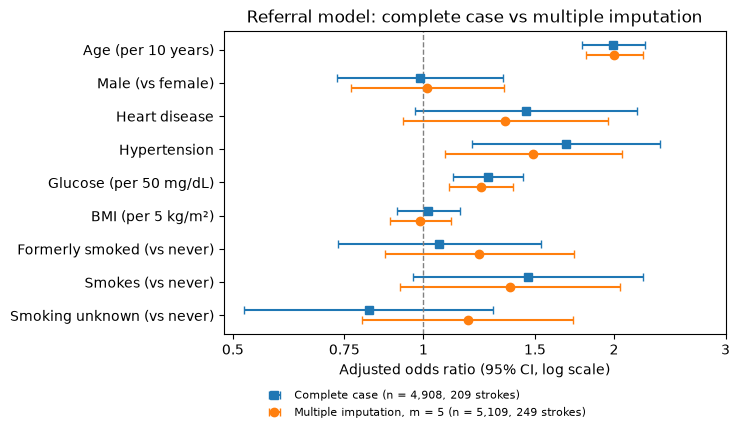

In [12]:
ok = X["bmi"].notna().to_numpy()
fit_cc = fit_sm_logit(X[ok], y[ok])
ci_cc = fit_cc.conf_int()
or_cmp = pd.DataFrame({
    "predictor": [LABELS[c] for c in MODEL_COLS],
    "OR_cc": np.exp(fit_cc.params[MODEL_COLS]), "ci_low_cc": np.exp(ci_cc.loc[MODEL_COLS, 0]),
    "ci_high_cc": np.exp(ci_cc.loc[MODEL_COLS, 1]), "p_cc": fit_cc.pvalues[MODEL_COLS],
    "OR_mi": or_mi.OR, "ci_low_mi": or_mi.ci_low, "ci_high_mi": or_mi.ci_high, "p_mi": or_mi.p_value,
}, index=MODEL_COLS)
or_cmp["ratio_mi_to_cc"] = or_cmp.OR_mi / or_cmp.OR_cc
or_cmp.to_csv(TABLES / "model_or_cc_vs_mi.csv", index_label="column", float_format=FLOAT_FMT)
print(f"Complete case: n = {ok.sum():,}, strokes = {y[ok].sum()} | MI: n = {len(y):,}, strokes = {y.sum()}")
display(or_cmp.assign(**{
    "Complete case OR (95% CI)": [fmt_ci(r.OR_cc, r.ci_low_cc, r.ci_high_cc) for r in or_cmp.itertuples()],
    "MI OR (95% CI)": [fmt_ci(r.OR_mi, r.ci_low_mi, r.ci_high_mi) for r in or_cmp.itertuples()],
})[["predictor", "Complete case OR (95% CI)", "MI OR (95% CI)", "ratio_mi_to_cc"]].set_index("predictor").round(2))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ypos = np.arange(len(MODEL_COLS))[::-1]
ax.errorbar(or_cmp.OR_cc, ypos + 0.15, xerr=[or_cmp.OR_cc - or_cmp.ci_low_cc, or_cmp.ci_high_cc - or_cmp.OR_cc],
            fmt="s", capsize=3, label=f"Complete case (n = {ok.sum():,}, {y[ok].sum()} strokes)")
ax.errorbar(or_cmp.OR_mi, ypos - 0.15, xerr=[or_cmp.OR_mi - or_cmp.ci_low_mi, or_cmp.ci_high_mi - or_cmp.OR_mi],
            fmt="o", capsize=3, label=f"Multiple imputation, m = {N_IMPUTATIONS} (n = {len(y):,}, {y.sum()} strokes)")
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xscale("log"); ax.set_yticks(ypos); ax.set_yticklabels(or_cmp.predictor)
ax.set_xlabel("Adjusted odds ratio (95% CI, log scale)")
ticks = [0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks]); ax.minorticks_off()
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.15), ncol=1, frameon=False)
ax.set_title("Referral model: complete case vs multiple imputation")
fig.tight_layout(); fig.savefig(FIGURES / "model_or_forest.png", bbox_inches="tight"); plt.show()

**Results.**
- Age, gender, glucose and BMI agree within about 3%. **Hypertension** moves from 1.68 to 1.49 and **heart disease** from 1.45 to 1.35 once the 40 strokes among BMI-missing patients are back in the data.
- The largest change is **smoking "Unknown"** (0.82 → 1.17), but both intervals are wide and include 1.
- MI uses all 249 strokes, so its intervals are a little narrower.
- **What MI cannot do (professor F4):** MI assumes BMI is missing at random given the other variables. Track 1 shows the BMI-missing group has 2.6 times the strokes expected from its covariates, which points to MNAR or reverse causation. Imputed BMI values cannot carry that excess risk. Since BMI itself has no association in either analysis, this mainly affects calibration for that group (see G2), not the ORs.

## G3. Diagnostics

| Check | How |
|-------|-----|
| Linearity of the logit | For age, glucose and BMI, one at a time: replace the linear term with a 4-df B-spline (as in notebooks 02 and 05) and compare by LR test (3 df). Main test on complete cases (one dataset, so the LR test is exact); repeated on each imputed dataset (range of p shown). |
| Influential points | Cook's distance from the complete-case GLM; refit without the 10 most influential patients and compare the ORs. |
| Collinearity | Variance inflation factors. |
| Separation / sparse cells | Largest coefficient SE; strokes per smoking level. |

,predictor,data,lr_chi2,df,p,p_imputed_min,p_imputed_max
0,Age (per 10 years),"Complete case (n = 4,908)",5.0083,3,0.1712,0.0532,0.0598
1,Glucose (per 50 mg/dL),"Complete case (n = 4,908)",0.4283,3,0.9343,0.7999,0.8228
2,BMI (per 5 kg/m²),"Complete case (n = 4,908)",1.6717,3,0.6432,0.4808,0.7738


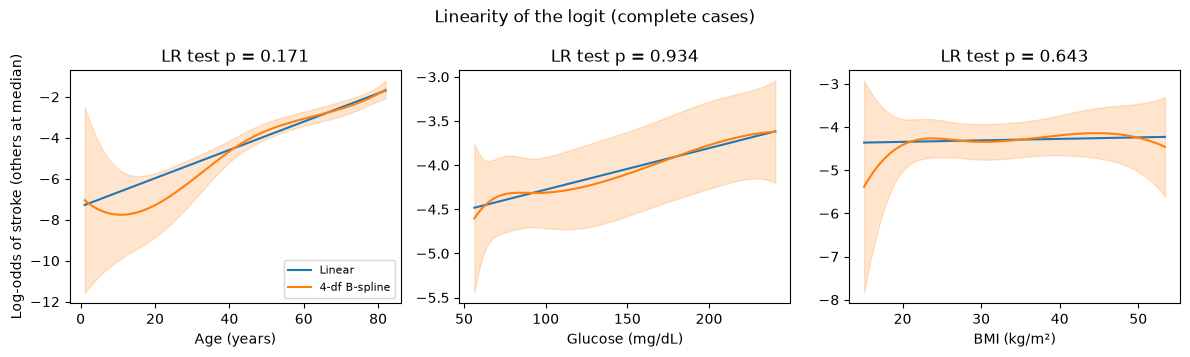

In [13]:
# Linearity of the logit: 4-df B-spline vs linear, one continuous predictor at a time (LR test, 3 df).
# Main analysis on complete cases (one dataset, so the LR test is exact); repeated on each imputed dataset.
lin_terms = " + ".join(MODEL_COLS)
def lr_spline(data, var):
    other = " + ".join(c for c in MODEL_COLS if c != var)
    f_lin = smf.logit(f"stroke ~ {var} + {other}", data).fit(disp=0)
    f_spl = smf.logit(f"stroke ~ bs({var}, df=4) + {other}", data).fit(disp=0)
    chi2 = 2 * (f_spl.llf - f_lin.llf)
    return chi2, stats.chi2.sf(chi2, 3), f_lin, f_spl

cc_data = X.loc[ok, MODEL_COLS].assign(stroke=y[ok])
lin_rows, spline_fits = [], {}
for var in ["age", "avg_glucose_level", "bmi"]:
    chi2, p, f_lin, f_spl = lr_spline(cc_data, var)
    spline_fits[var] = (f_lin, f_spl)
    p_imp = [lr_spline(Xm[MODEL_COLS].assign(stroke=y), var)[1] for Xm in Xs]
    lin_rows.append({"predictor": LABELS[var], "data": f"Complete case (n = {ok.sum():,})", "lr_chi2": chi2, "df": 3, "p": p,
                     "p_imputed_min": min(p_imp), "p_imputed_max": max(p_imp)})
lin = pd.DataFrame(lin_rows)
lin.to_csv(TABLES / "model_linearity.csv", index=False, float_format=FLOAT_FMT)
display(lin.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ref = cc_data[MODEL_COLS].median().to_frame().T
for ax, var in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    f_lin, f_spl = spline_fits[var]
    lo, hi = cc_data[var].quantile([0.01, 0.99])
    grid = ref.loc[ref.index.repeat(200)].reset_index(drop=True)
    grid[var] = np.linspace(lo, hi, 200)
    for f, lab in [(f_lin, "Linear"), (f_spl, "4-df B-spline")]:
        pr_ = f.get_prediction(grid).summary_frame()
        lo_ = np.log(pr_["predicted"] / (1 - pr_["predicted"]))
        ax.plot(grid[var] * UNITS[var], lo_, label=lab)
        if lab != "Linear":
            ax.fill_between(grid[var] * UNITS[var], np.log(pr_.ci_lower / (1 - pr_.ci_lower)),
                            np.log(pr_.ci_upper / (1 - pr_.ci_upper)), alpha=0.2, color="C1")
    ax.set_xlabel({"age": "Age (years)", "avg_glucose_level": "Glucose (mg/dL)", "bmi": "BMI (kg/m²)"}[var])
    ax.set_title(f"LR test p = {lin.set_index('predictor').loc[LABELS[var], 'p']:.3f}")
axes[0].set_ylabel("Log-odds of stroke (others at median)"); axes[0].legend(fontsize=8)
fig.suptitle("Linearity of the logit (complete cases)")
fig.tight_layout(); fig.savefig(FIGURES / "model_linearity.png", bbox_inches="tight"); plt.show()

Cook's D > 4/n (0.00081): 223 patients; max D = 0.0129


,row_id,age,gender,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,stroke,cooks_d,leverage
245,245,14.0,Female,0,0,57.93,30.9,Unknown,1,0.0129,0.0002
113,113,45.0,Female,0,0,224.10,56.6,never smoked,1,0.0113,0.0033
79,79,43.0,Male,0,0,143.43,45.9,Unknown,1,0.0088,0.0012
49,49,39.0,Female,1,0,58.09,39.2,smokes,1,0.0085,0.0017
225,225,57.0,Female,0,1,216.58,31.0,Unknown,1,0.0084,0.0059
121,121,53.0,Female,1,0,62.55,30.3,Unknown,1,0.0074,0.0022
80,80,59.0,Male,0,0,96.16,44.1,Unknown,1,0.0074,0.0024
100,100,64.0,Male,0,1,74.10,28.8,Unknown,1,0.0072,0.0041
217,217,55.0,Female,1,1,210.40,40.0,smokes,1,0.0072,0.0129
21,21,52.0,Female,1,0,233.29,48.9,never smoked,1,0.0070,0.0057


,predictor,OR_all,OR_without_top10,pct_change
age,Age (per 10 years),1.995,2.116,6.088
male,Male (vs female),0.989,1.023,3.439
heart_disease,Heart disease,1.452,1.313,-9.562
hypertension,Hypertension,1.678,1.579,-5.875
avg_glucose_level,Glucose (per 50 mg/dL),1.265,1.266,0.131
bmi,BMI (per 5 kg/m²),1.017,0.965,-5.136
smoke_former,Formerly smoked (vs never),1.059,1.079,1.834
smoke_current,Smokes (vs never),1.461,1.458,-0.198
smoke_unknown,Smoking unknown (vs never),0.819,0.651,-20.498


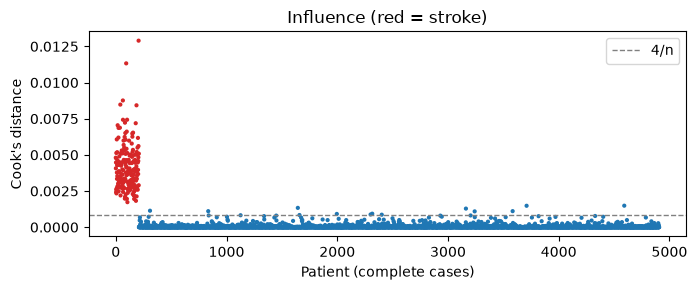

,predictor,VIF
0,Age (per 10 years),1.45
1,Male (vs female),1.02
2,Heart disease,1.10
3,Hypertension,1.11
4,Glucose (per 50 mg/dL),1.10
5,BMI (per 5 kg/m²),1.18
6,Formerly smoked (vs never),1.24
7,Smokes (vs never),1.19
8,Smoking unknown (vs never),1.44


Largest coefficient SE (complete case): 0.571 | strokes per smoking group: {'Unknown': 47, 'formerly smoked': 70, 'never smoked': 90, 'smokes': 42}


In [14]:
# Influential observations (complete-case GLM; Cook's distance)
glm_cc = sm.GLM(y[ok], sm.add_constant(X.loc[ok, MODEL_COLS]), family=sm.families.Binomial()).fit()
infl = glm_cc.get_influence()
cooks = infl.cooks_distance[0]
cc_frame = df.loc[ok, ["row_id", "age", "gender", "hypertension", "heart_disease", "avg_glucose_level", "bmi",
                       "smoking_status", "stroke"]].assign(cooks_d=cooks, leverage=infl.hat_matrix_diag)
top = cc_frame.sort_values("cooks_d", ascending=False).head(10)
top.to_csv(TABLES / "model_influence_top10.csv", index=False, float_format=FLOAT_FMT)
cut = 4 / ok.sum()
print(f"Cook's D > 4/n ({cut:.5f}): {(cooks > cut).sum()} patients; max D = {cooks.max():.4f}")
display(top.round(4))

# Refit without the 10 most influential patients
keep = ~cc_frame.index.isin(top.index)
fit_drop = fit_sm_logit(X.loc[ok][keep], y[ok][keep])
or_drop = pd.DataFrame({"predictor": [LABELS[c] for c in MODEL_COLS],
                        "OR_all": np.exp(fit_cc.params[MODEL_COLS]),
                        "OR_without_top10": np.exp(fit_drop.params[MODEL_COLS])}, index=MODEL_COLS)
or_drop["pct_change"] = 100 * (or_drop.OR_without_top10 / or_drop.OR_all - 1)
or_drop.to_csv(TABLES / "model_influence_or_change.csv", index_label="column", float_format=FLOAT_FMT)
display(or_drop.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(np.arange(ok.sum()), cooks, s=4, c=np.where(y[ok] == 1, "C3", "C0"))
ax.axhline(cut, ls="--", color="grey", lw=1, label="4/n")
ax.set_xlabel("Patient (complete cases)"); ax.set_ylabel("Cook's distance"); ax.legend()
ax.set_title("Influence (red = stroke)")
fig.tight_layout(); fig.savefig(FIGURES / "model_influence.png", bbox_inches="tight"); plt.show()

# Collinearity and separation
Zc = sm.add_constant(X.loc[ok, MODEL_COLS])
vif = pd.DataFrame({"predictor": [LABELS[c] for c in MODEL_COLS],
                    "VIF": [variance_inflation_factor(Zc.to_numpy(), i + 1) for i in range(len(MODEL_COLS))]})
vif.to_csv(TABLES / "model_vif.csv", index=False, float_format=FLOAT_FMT)
display(vif.round(2))
print("Largest coefficient SE (complete case):", fit_cc.bse.max().round(3), "| strokes per smoking group:",
      df.groupby("smoking_status", observed=True)["stroke"].sum().to_dict())

**Diagnostic results.**
- **Linearity is not rejected:** age p = 0.17 (complete case; 0.053 to 0.060 across imputations), glucose p = 0.93, BMI p = 0.64. The age spline bends only below about 20 years, where there are just 2 strokes and the band is very wide. **Linear terms are kept**, which also keeps the ORs in clinical units. (Track 4's P3 found p = 0.039 for age with no other covariates; adjusting for the other risk factors absorbs most of the curvature.)
- **Influence is small:** max Cook's D = 0.013. The 10 most influential patients are all strokes in patients the model rates as low risk (young or without risk factors), which is what a rare outcome produces. Dropping them changes each OR by under 10%, except smoking "Unknown" (−20%; its interval was already wide). No patient was removed.
- **Collinearity:** all VIFs ≤ 1.45.
- **Separation:** none. The largest SE is 0.57 and every smoking level has 42 or more strokes.

## B2. Methods paragraph for the report (pooling decision)

> Body-mass index was missing for 201 patients (3.9%). We used multiple imputation by Bayesian linear regression of log(BMI) on the other predictors and on marital status, work type and residence, drawing the regression parameters from their posterior for each imputation (m = 5). For inference, the outcome was included in the imputation model and the odds ratios from the m completed datasets were combined with Rubin's rules; the fraction of missing information was at most 0.09, and m = 20 gave the same estimates to two decimals. For validation we used stratified 5-fold cross-validation with imputation performed inside each fold: the imputation model was fitted on the training fold only, without the outcome, and applied to both the training and the test fold, so no information from test patients reached the model. Within each fold we fitted one logistic model per imputed dataset and **averaged the m predicted probabilities for each test patient**, which mirrors how the model would be used for a new patient and gives a single prediction to which a referral threshold can be applied. This choice was fixed before any performance was computed. We report a complete-case analysis alongside (B3). Imputation assumes BMI is missing at random given the other variables; the analysis of the missing-BMI group (section X) suggests it is not, so imputation cannot recover the excess risk in that group.

## Summary and hand-offs

**Main findings (for the report).**
1. The referral model is well calibrated out of sample (calibration intercept about 0, slope 0.95, 0.85 to 1.07) and discriminates well (AUC 0.839, 0.818 to 0.859), **but almost all of that comes from age**: age alone reaches AUC 0.833, and the paired gain is 0.006 (−0.001 to 0.013).
2. Adjusted ORs (Rubin's rules): age 2.00 per 10 years, hypertension 1.49, glucose 1.23 per 50 mg/dL. Heart disease, smoking, gender and BMI have intervals that include 1.
3. Complete case and MI agree closely. MI recovers the 40 strokes in BMI-missing patients but cannot recover their excess risk (MNAR).
4. Diagnostics: linearity holds, no influential points that change conclusions, no collinearity or separation.

**For Track 5 (A2–A4).**
- Use `data/interim/oof_final.csv`: column `p_mi` is the referral model; `p_age_only` and `p_intercept` are the decision-curve comparators; `stroke` is the outcome. Run this notebook first (about 70 s); `run_all.py` runs it before notebook 07.
- For the whole-pipeline bootstrap of the threshold (A4), resample patients and re-run the same pipeline:

```python
from src.data import load_raw
from src.modeling import prepare, oof_predictions
from src.config import SEED, N_BOOT_PIPELINE

df = prepare(load_raw())
for b in range(N_BOOT_PIPELINE):
    db = df.sample(n=len(df), replace=True, random_state=SEED + b).reset_index(drop=True)
    o = oof_predictions(db, seed=SEED + b, models=("mi",))   # about 1 s per resample
    # ... threshold that minimises expected cost on o["stroke"], o["p_mi"]
```
- Note the calibration wobble in the 2–6% band (G4).

**For Track 1 (D4).** Numbers for the missing-indicator paragraph are in `model_performance_differences.csv` (AUC +0.010, 0.004 to 0.017); the reasoning is in G2.

**For Track 4 (H2, G5).** `oof_final.csv` has `age`, `gender` and `p_mi` per patient for the FN/FP/PPV table by group, once the threshold is chosen.

**For Track 6.** Figures: `model_calibration.png`, `model_or_forest.png`, `model_linearity.png`, `model_bmi_imputation_check.png`, `model_influence.png`. Every number above comes from a CSV in `results/tables/model_*.csv`.